# Choose an Earth observation before choosing an index

**Learning question:** Which combination of pixel support, revisit time and spectral information could answer a bounded environmental question?

Original Atlas resolution and observation-design exercises complement official ARSET learning resources. The source repository is README-only.

This introductory calculation is an original **synthetic** teaching exercise. Full source lessons and their actual data status are separately described below.


## Predict before running

Compare spatial, temporal, spectral and radiometric resolution separately. A finer pixel cannot recover an observation missed between acquisitions; a dense time series cannot identify a spectral property its sensor never measured. Cloud and QA masks change coverage. Match the measurement dates and footprint to the decision before computing an index.


In [1]:
from IPython.display import SVG, display
from html import escape

def svg(body, title, description, width=760, height=330):
    label = escape(title, quote=True)
    display(SVG(f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" role="img" aria-label="{label}"><title>{escape(title)}</title><desc>{escape(description)}</desc><rect width="100%" height="100%" fill="#f5f5ef" rx="12"/>{body}</svg>'))

def bars(values, title, unit):
    print(title + ' | ' + unit + ':', {k:round(v,3) for k,v in values.items()})
    n = len(values)
    height = max(250, 82 + n*36)
    maximum = max(max(values.values()), 1)
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18" fill="#123c45">{escape(title)}</text>'
    for i,(key,value) in enumerate(values.items()):
        y=58+i*36
        body += f'<text x="22" y="{y+17}" font-family="sans-serif" font-size="13">{escape(str(key))}</text><rect x="205" y="{y}" width="{max(0,value)/maximum*440:.2f}" height="23" rx="3" fill="#16756b"/><text x="{213+max(0,value)/maximum*440:.2f}" y="{y+17}" font-family="sans-serif" font-size="13">{value:.2f}</text>'
    body += f'<text x="205" y="{height-15}" font-family="sans-serif" font-size="12">zero baseline · {escape(unit)}</text>'
    svg(body, title, 'Values are printed as a text alternative; consult the chart title for data status.', height=height)

def grid(values, columns, title):
    print(title + ':', [round(v,3) for v in values])
    maximum = max(max(values),1)
    size = 54
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text>'
    for i,v in enumerate(values):
        x=25+(i%columns)*size; y=52+(i//columns)*size
        light=92-50*v/maximum
        body += f'<rect x="{x}" y="{y}" width="50" height="50" fill="hsl(169,45%,{light:.1f}%)" stroke="#123c45"/><text x="{x+25}" y="{y+29}" text-anchor="middle" font-family="sans-serif" font-size="14" fill="#061c21">{v:.1f}</text>'
    svg(body,title,'Synthetic grid with values printed in each cell; no actual boundaries.',height=max(220,70+((len(values)+columns-1)//columns)*size))

def lines(series, title, xunit, yunit):
    print(title + ':', {k:[round(v,3) for v in vs] for k,vs in series.items()})
    maximum=max(max(vs) for vs in series.values()) or 1
    body=f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text><path d="M55 55V265H710" fill="none" stroke="#123c45"/>'
    for j,(name,vs) in enumerate(series.items()):
        color=['#16756b','#a34712','#41449c'][j%3]
        pts=' '.join(f'{55+i*650/max(1,len(vs)-1):.1f},{265-v*200/maximum:.1f}' for i,v in enumerate(vs))
        body+=f'<polyline points="{pts}" fill="none" stroke="{color}" stroke-width="3"/><text x="{60+j*220}" y="310" font-family="sans-serif" font-size="13" fill="{color}">{escape(name)}</text>'
    body+=f'<text x="55" y="288" font-family="sans-serif" font-size="12">{escape(xunit)} → · {escape(yunit)} ↑ · y starts at zero</text>'
    svg(body,title,'Synthetic series; printed values are the text alternative.')


Fictional design candidates, not sensor product specifications: {'fine spatial': {'pixel_m': 10, 'revisit_days': 10}, 'frequent view': {'pixel_m': 250, 'revisit_days': 1}, 'regional detail': {'pixel_m': 30, 'revisit_days': 16}}
Synthetic expected opportunities in a seven-day window | opportunities before clouds: {'fine spatial': 0.7, 'frequent view': 7.0, 'regional detail': 0.438}


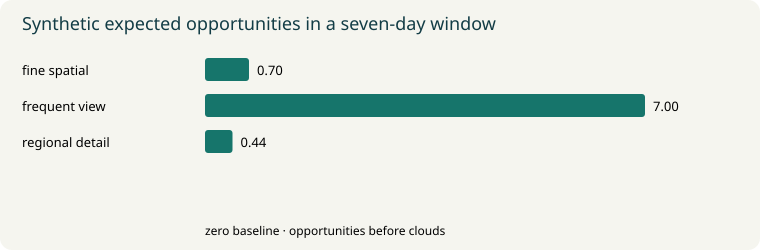

In [2]:
candidates = {'fine spatial':{'pixel_m':10,'revisit_days':10}, 'frequent view':{'pixel_m':250,'revisit_days':1}, 'regional detail':{'pixel_m':30,'revisit_days':16}}
window_days = 7
expected = {k:window_days/v['revisit_days'] for k,v in candidates.items()}
print('Fictional design candidates, not sensor product specifications:', candidates)
bars(expected, 'Synthetic expected opportunities in a seven-day window', 'opportunities before clouds')


## Interpret the result

This illustrative calculation compares potential opportunities, not usable acquisitions or scientific accuracy. A seven-day event may be missed by a sixteen-day cycle; 250 m support may mix a small water body with surrounding land. Band ratios do not establish health effects. Inspect the QA, cloud cover, projection, units and calibration before comparing scenes.

## Change one thing

Set window_days to 30, then add an explicit assumed cloud-free fraction. Explain why multiplying by that fraction is a scenario rather than a forecast. Design a water, fire, crop or air-quality question with a footprint, date window, target observable, validation observation and a stopping rule.


## Source course and scientific boundaries

Begin with [NASA Earth Action](https://science.nasa.gov/earth-science/earth-action/), the [NASAARSET code organization](https://github.com/NASAARSET), and the [Fundamentals course](https://arset.unhosting.site/course/view.php?id=26), which may require an account. Those are external learning references, not launches of this README-only project. Resolution trade-offs, band calibration, compositing and projections are prerequisites for a defensible application. Write the expected observable and an alternative explanation before choosing an NDVI/NDWI-like ratio. No NASA artwork or course handouts are imported; [NASA media policy](https://www.nasa.gov/nasa-brand-center/images-and-media/) remains separately scoped.

[Complete local course guide](../../courses/nasa-arset-experiments/index.ipynb) ? [Notebook library](../../notebook-library.ipynb)

## Sources, attribution and limits

[Reviewed source README](https://github.com/jltobias/JupyterLite-NASA-ARSET-Experiments/blob/7f2ba5bf12ef44b07c839a441ea398aa08ad3569/README.md) · [Source repository](https://github.com/jltobias/JupyterLite-NASA-ARSET-Experiments)

README-only source: no original source notebooks, dataset, Book, Lab or hosted project deployment are supplied. This is independently authored Atlas teaching material, not a NASA/ARSET course or endorsed product. Official slides, videos, handouts, NASA logos and third-party course repositories are not copied. Official ARSET resources remain external and retain their own terms.



[Central references](../../references.ipynb)
